# 02 — All-track Transformer dataset preprocessing

This walkthrough uses **`final_all_tracks/all_tracks_sequences_readable.csv`** as its inspection table. It follows saved categorical encoding, melody pitch and timing normalization, note padding, musical context, target masking, and sequence construction across all three splits. It reads existing artifacts and never fits vocabularies, rebuilds data, or trains a model.

The readable CSV contains the **results** of preprocessing. To demonstrate how those results were produced, selected real beats are joined back to their Phase 1 training-event CSVs and passed through the existing saved encoder. Audit fields and reference targets stay separate from model inputs.

In [1]:
from pathlib import Path
import csv, gc, hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
candidates = [here, *here.parents, here / 'vocal-harmonization']
ROOT = next(p for p in candidates if (p / 'experiments/rahul/src/encode_features.py').is_file())
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from experiments.rahul.src.encode_features import FeatureEncoder, CATEGORICAL, load_events
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset

COMPONENT = ROOT / 'experiments/rahul'
OUT = COMPONENT / 'outputs/model_preprocessing/final_all_tracks_quality_v4_m4'
CSV = OUT / 'all_tracks_sequences_readable.csv'
def read_json(path): return json.loads(path.read_text(encoding='utf-8'))
config = read_json(OUT / 'preprocessing_config.json')
schema = read_json(OUT / 'all_tracks_sequences_readable_schema.json')
export_report = read_json(OUT / 'all_tracks_sequences_readable_validation.json')
encoder = FeatureEncoder.load(OUT)  # Load training-fitted mappings; no fit/save.
index = pd.read_csv(OUT / 'all_tracks_csv_index.csv', dtype={'track_id': str})
csv.field_size_limit(64 * 1024 * 1024)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_rows', 40)
protected = {p: (p.stat().st_size, p.stat().st_mtime_ns) for p in OUT.iterdir() if p.is_file()}
print('Inspection CSV:', CSV.relative_to(ROOT))
print('CSV size (GB):', round(CSV.stat().st_size / 1e9, 3))
display(index.groupby('split', sort=False).agg(tracks=('track_id','nunique'), sequences=('sequences','sum'), real_positions=('real_positions','sum'), padded_positions=('padded_positions','sum')))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Inspection CSV: experiments\rahul\outputs\model_preprocessing\final_all_tracks_quality_v4_m4\all_tracks_sequences_readable.csv
CSV size (GB): 0.349


,tracks,sequences,real_positions,padded_positions
split,,,,
train,470,23537,186594,1702
validation,23,1429,11336,96
test,32,1798,14278,106


## 1. Read all-track metadata in bounded chunks

The readable CSV repeats complete four-slot melody tensors at every position. We scan only identity, chord and beat-mask columns in chunks, aggregate counts, and retain metadata for the first two sequences and the final sequence of each split. The full tensor strings are loaded only for those selected windows. No giant DataFrame is created.

In [2]:
meta_cols = ['split','sequence_id','position_in_sequence','track_id','beat_index','is_padding',
             'basic_chord_decoded','basic_root_decoded','basic_quality_decoded',
             'inputs__basic_root_ids','inputs__basic_quality_ids','reference_chord_decoded','inputs__beat_attention_mask','targets__target_loss_mask']
summary = {}
unknown_chunks = []
for chunk in pd.read_csv(CSV, usecols=meta_cols, chunksize=4096, dtype={'track_id':str}):
    unknown = (chunk['basic_root_decoded'].str.upper().eq('UNK') | chunk['basic_quality_decoded'].str.upper().eq('UNK')) & ~chunk['is_padding']
    if unknown.any():
        unknown_chunks.append(chunk.loc[unknown].copy())
    for split, part in chunk.groupby('split', sort=False):
        state = summary.setdefault(split, dict(rows=0, real=0, padding=0, supervised=0, tracks=set(), sequences=set(), basic={}))
        state['rows'] += len(part)
        state['real'] += int(part['inputs__beat_attention_mask'].sum())
        state['padding'] += int(part['is_padding'].sum())
        state['supervised'] += int(part['targets__target_loss_mask'].sum())
        state['tracks'].update(part.track_id)
        state['sequences'].update(part.sequence_id)
        for label, count in part.loc[~part.is_padding, 'basic_chord_decoded'].value_counts().items():
            state['basic'][label] = state['basic'].get(label, 0) + int(count)
summary_table = pd.DataFrame([dict(split=k, rows=v['rows'], real_positions=v['real'], padding=v['padding'],
    supervised=v['supervised'], tracks=len(v['tracks']), sequences=len(v['sequences'])) for k,v in summary.items()])
display(summary_table)
selected_ids = {k: {min(v['sequences']), min(v['sequences'])+1, max(v['sequences'])} for k,v in summary.items()}
# CSV rows are sorted by split then sequence; retain only selected full windows.
selected = []
with CSV.open(encoding='utf-8', newline='') as stream:
    for row in csv.DictReader(stream):
        if int(row['sequence_id']) in selected_ids[row['split']]:
            selected.append(row)
sample = pd.DataFrame(selected)
for col in ('sequence_id','position_in_sequence','beat_index'):
    sample[col] = sample[col].astype(int)
for col, spec in schema['columns'].items():
    if col.startswith(('inputs__','targets__')) or spec.get('serialization') in ('JSON list','JSON boolean'):
        sample[col] = sample[col].map(json.loads)
print('Full tensor rows retained for inspection:', len(sample))
display(sample[meta_cols].head(16))


,split,rows,real_positions,padding,supervised,tracks,sequences
0,train,188296,186594,1702,184889,470,23537
1,validation,11432,11336,96,11231,23,1429
2,test,14384,14278,106,14077,32,1798


Full tensor rows retained for inspection: 72


,split,sequence_id,position_in_sequence,track_id,beat_index,is_padding,basic_chord_decoded,basic_root_decoded,basic_quality_decoded,inputs__basic_root_ids,inputs__basic_quality_ids,reference_chord_decoded,inputs__beat_attention_mask,targets__target_loss_mask
0,train,0,0,1079196,0,False,G,G,maj,17,10,G:maj,True,True
1,train,0,1,1079196,1,False,G,G,maj,17,10,G:maj,True,True
2,train,0,2,1079196,2,False,G,G,maj,17,10,G:maj,True,True
3,train,0,3,1079196,3,False,G,G,maj,17,10,G:maj,True,True
4,train,0,4,1079196,4,False,D,D,maj,12,10,D:maj,True,True
5,train,0,5,1079196,5,False,D,D,maj,12,10,D:maj,True,True
6,train,0,6,1079196,6,False,D,D,maj,12,10,D:maj,True,True
7,train,0,7,1079196,7,False,D,D,maj,12,10,D:maj,True,True
8,train,1,0,1079196,8,False,Em,E,min,13,11,E:min,True,True
9,train,1,1,1079196,9,False,Em,E,min,13,11,E:min,True,True


## 2. Inspect every exported column and its role

`inputs__*` columns are the actual numerical model inputs; `targets__*` are supervision. Metadata and decoded labels are inspection aids. `beat_index` is integer source metadata (`-1` for padding), while `inputs__beat_index` is a float tensor (zero-filled padding). Sequence identity is **(split, sequence_id)** because IDs restart in each split.

In [3]:
display(pd.DataFrame([{'column': k, 'role': v.get('role','identity'), 'meaning': v['meaning']} for k,v in schema['columns'].items()]))
print('Saved input selection:', config['selected_input_columns'])
print('Target:', config['target_column'], '| validity source:', config['mask_column'])

,column,role,meaning
0,split,identity,"Archive split: train, validation, or test."
1,sequence_id,identity,Zero-based archive sequence index; equals SavedSequenceDataset item index.
2,position_in_sequence,identity,Zero-based position within the stored sequence.
3,track_id,metadata,"Exact track_ids value, repeated for all positions in the sequence."
4,beat_index,metadata,Exact int64 source beat_indices value; -1 at padded positions. Distinct from the floating input ...
...,...,...,...
45,melody_sources_decoded,decoded input,"Saved extraction-source tokens per note slot, including PAD."
46,melody_midi_rounded_decoded,decoded input,"Rounded absolute MIDI values, with explicit PAD/UNK strings. Original fractional MIDI is represe..."
47,melody_pitch_classes_decoded,decoded input,"Pitch classes 0..11, with explicit PAD/UNK strings."
48,genre_vocabulary,decoded input,Saved genre coordinate order. Repeated to make each vector independently interpretable.


Saved input selection: ['bar_number', 'basic_chord_canonical', 'basic_quality', 'basic_root', 'beat_index', 'beat_position', 'event_duration', 'genre_tags', 'harmonic_function', 'key', 'key_confidence', 'melody_durations', 'melody_midi', 'melody_overlap_durations', 'melody_pitch_classes', 'melody_relative_start', 'melody_sources', 'mode', 'next_basic_chord', 'previous_basic_chord', 'roman_numeral']
Target: reference_chord_canonical | validity source: target_valid


## 3. Join selected positions to their original beat events

Only the source files for the selected tracks are read. The source beat index joins a CSV position back to a typed Phase 1 event. This provides the original fractional MIDI, timing and reference labels that cannot always be reconstructed from tokens or ignored targets.

In [4]:
source_rows = {}
for track in sample.track_id.unique():
    source_name = f'track_{int(track):07d}'
    source_path = ROOT / config['phase1_output_root'] / source_name / f'{source_name}_training_events.csv'
    events, _ = load_events(source_path)
    source_rows[track] = {int(r['beat_index']): r for r in events}
real_sample = sample.loc[~sample.is_padding].copy()
def source_for(row): return source_rows[row.track_id][int(row.beat_index)]
display(pd.DataFrame([dict(split=r.split, track_id=r.track_id, beat_index=r.beat_index,
    raw_basic=source_for(r)['basic_chord'], canonical_basic=source_for(r)['basic_chord_canonical'],
    basic_id=r['inputs__basic_chord_ids'], decoded=r.basic_chord_decoded,
    raw_reference=source_for(r)['reference_chord'], target_id=r['targets__target_chord_ids'],
    decoded_target=r.reference_chord_decoded) for _,r in real_sample.head(12).iterrows()]))


,split,track_id,beat_index,raw_basic,canonical_basic,basic_id,decoded,raw_reference,target_id,decoded_target
0,train,1079196,0,G,G,69,G,G:maj,378,G:maj
1,train,1079196,1,G,G,69,G,G:maj,378,G:maj
2,train,1079196,2,G,G,69,G,G:maj,378,G:maj
3,train,1079196,3,G,G,69,G,G:maj,378,G:maj
4,train,1079196,4,D,D,37,D,D:maj,214,D:maj
5,train,1079196,5,D,D,37,D,D:maj,214,D:maj
6,train,1079196,6,D,D,37,D,D:maj,214,D:maj
7,train,1079196,7,D,D,37,D,D:maj,214,D:maj
8,train,1079196,8,Em,Em,54,Em,E:min,260,E:min
9,train,1079196,9,Em,Em,54,Em,E:min,260,E:min


## 4. Categorical chord and musical-context encoding

The saved training vocabulary maps labels to category IDs; IDs do not express musical distance. Current, previous and next basic chords share a vocabulary. PAD, UNK, N, START and END have distinct roles. Detailed reference classes use a separate target vocabulary. Key, mode, confidence category, Roman numeral and harmonic function have their own mappings. Genre is a sequence-level multi-hot vector, repeated even on padded positions.

In [5]:
display(pd.DataFrame([dict(feature=tensor, source_field=field,
    vocabulary_size=len(encoder.vocabs[field].tokens)) for tensor,field in CATEGORICAL.items()]))
context_cols = ['split','track_id','beat_index','basic_chord_decoded','previous_basic_chord_decoded',
    'next_basic_chord_decoded','key_decoded','mode_decoded','key_confidence_decoded','roman_decoded','harmonic_function_decoded',
    'genre_labels_decoded','inputs__genre_features']
display(real_sample[context_cols].groupby('track_id', sort=False).head(2))
display(pd.DataFrame({'genre_coordinate': range(len(encoder.genres)), 'genre': encoder.genres}))
display(pd.DataFrame({'target_class_id': range(len(encoder.targets.tokens)), 'label': encoder.targets.tokens}).head(20))


,feature,source_field,vocabulary_size
0,basic_chord_ids,basic_chord_canonical,82
1,basic_root_ids,basic_root,18
2,basic_quality_ids,basic_quality,13
3,previous_basic_chord_ids,previous_basic_chord,82
4,next_basic_chord_ids,next_basic_chord,82
5,key_ids,key,18
6,mode_ids,mode,8
7,key_confidence_ids,key_confidence,10
8,roman_ids,roman_numeral,18
9,harmonic_function_ids,harmonic_function,9


,split,track_id,beat_index,basic_chord_decoded,previous_basic_chord_decoded,next_basic_chord_decoded,key_decoded,mode_decoded,key_confidence_decoded,roman_decoded,harmonic_function_decoded,genre_labels_decoded,inputs__genre_features
0,train,1079196,0,G,START,G,G,major,medium,I,tonic,"[dance, poprock]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ..."
1,train,1079196,1,G,G,G,G,major,medium,I,tonic,"[dance, poprock]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ..."
16,train,917543,424,N,N,N,Eb,major,low,N,unknown,"[easylistening, pop, singersongwriter]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ..."
17,train,917543,425,N,N,N,Eb,major,low,N,unknown,"[easylistening, pop, singersongwriter]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ..."
24,validation,156888,0,N,START,N,C,major,medium,N,unknown,[],"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
25,validation,156888,1,N,N,Fm,C,major,medium,N,unknown,[],"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
40,validation,901684,608,N,N,END,G,major,high,N,unknown,"[alternative, indie, pop]","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
48,test,156887,0,N,START,N,F,major,medium,N,unknown,[],"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
49,test,156887,1,N,N,Am,F,major,medium,N,unknown,[],"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
64,test,855373,336,A,A,A,C,major,low,unknown,unknown,"[UNK, dance, electronic, house]","[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ..."


,genre_coordinate,genre
0,0,UNK
1,1,acidjazz
2,2,alternative
3,3,ambient
4,4,blues
...,...,...
58,58,symphonic
59,59,synthpop
60,60,techno
61,61,trance


,target_class_id,label
0,0,PAD
1,1,UNK
2,2,N
3,3,A#:7
4,4,A#:7/2
5,5,A#:7/3
6,6,A#:7/5
7,7,A#:7/6
8,8,A#:7/b2
9,9,A#:aug


### Rebuilt quality families: reference chords and actual numerical IDs

The active dataset is **final_all_tracks_quality_v4_m4**, rebuilt with these rules:

| Reference quality (source or shorthand) | Basic quality |
|---|---|
| maj, 6, maj7, maj9, add9 | maj |
| min/m, min7/m7, min9/m9, min11/m11 | min |
| 7, 9, 13, 7b9 | dom |
| dim, dim7 | dim |
| hdim7, m7b5, co7 | hdim |
| aug, + | aug |
| sus2, sus4 | sus |

Existing minor/major modifiers remain in their families, and dominant 11 is handled consistently with dominant 9/13. Half-diminished classification is checked before minor/diminished classification. N is preserved. These rules inspect the isolated quality, not arbitrary substrings of the root or inversion.

Basic representatives are C, Cm, C7, Cdim, Cm7b5, Caug and Csus. Extensions and inversions remain intact in detailed reference labels. Basic labels, canonical labels, quality IDs, neighboring basic IDs and basic-derived Roman/function context are regenerated together. Dominant chords receive a dominant V function only at the estimated key's fifth; other non-diatonic cases remain unknown. Half-diminished context uses its diminished underlying triad.

All feature vocabularies were fitted on the same training split. **Use inputs__basic_quality_ids with this snapshot's saved vocabulary.** Source targets, target IDs/masks, melody, timing, genres, beat metadata and split assignments were verified unchanged. The following examples compare the previous v2 snapshot with the rebuilt v3 dataset, including changes from maj to dom and dim to hdim.

In [6]:
quality_rebuild = read_json(OUT / 'quality_rebuild_validation.json')
assert quality_rebuild['status'] == 'passed'
display(pd.DataFrame([{'quality': k, 'corrected_positions': v} for k,v in quality_rebuild['corrected_quality_positions'].items()]))
display(pd.DataFrame(quality_rebuild['corrected_examples']))
quality_vocab = encoder.vocabs['basic_quality']
display(pd.DataFrame({'basic_quality': quality_vocab.tokens, 'inputs__basic_quality_ids': range(len(quality_vocab.tokens))}))
for example in quality_rebuild['corrected_examples']:
    assert quality_vocab.decode(example['new_basic_quality_id']) == example['new_basic_quality']
display(pd.DataFrame([{'changed_source_column': k, 'positions': v} for k,v in quality_rebuild['source_changed_columns'].items()]))
print('Remaining unsupported source qualities:', quality_rebuild['remaining_unknown_source_qualities'])
print(quality_rebuild['preserved'])

# Show every requested spelling even when that spelling has no source occurrences.
from experiments.rahul.src.build_synthetic_dataset import basic_quality_family
rules = {'maj':['maj','6','maj7','maj9','add9'], 'min':['min','m','m7','m9','m11'],
         'dom':['7','9','13','7b9'], 'dim':['dim','dim7'],
         'hdim':['hdim7','m7b5','co7'], 'aug':['aug','+'], 'sus':['sus2','sus4']}
rule_rows=[]
for family, spellings in rules.items():
    for spelling in spellings:
        assert basic_quality_family(spelling)==family
        token_id=quality_vocab.encode(family)
        assert quality_vocab.decode(token_id)==family
        rule_rows.append({'reference_quality':spelling,'basic_quality':family,'inputs__basic_quality_ids':token_id})
display(pd.DataFrame(rule_rows))


,quality,corrected_positions
0,dom,7988
1,hdim,234
2,aug,58


,track_id,beat_index,reference_chord,old_basic_quality,new_basic_quality,old_basic_quality_id,new_basic_quality_id,old_basic_chord,new_basic_chord
0,382,43,C:7,maj,dom,7,8,C,C7
1,382,275,G:7,maj,dom,7,8,G,G7
2,382,280,D:7,maj,dom,7,8,D,D7
3,387,6,Ab:7,maj,dom,7,8,Ab,Ab7
4,387,32,F:7,maj,dom,7,8,F,F7
5,387,87,G:hdim7,dim,hdim,6,9,Gdim,Gm7b5
6,387,189,G:hdim7/b3,dim,hdim,6,9,Gdim,Gm7b5
7,387,264,C:hdim7,dim,hdim,6,9,Cdim,Cm7b5
8,7392,105,B:hdim7,dim,hdim,6,9,Bdim,Bm7b5
9,43885,1,C:aug,UNK,aug,1,6,UNK,Caug


,basic_quality,inputs__basic_quality_ids
0,PAD,0
1,UNK,1
2,N,2
3,START,3
4,END,4
5,unknown,5
6,aug,6
7,dim,7
8,dom,8
9,hdim,9


,changed_source_column,positions
0,next_basic_chord,8274
1,basic_chord,8280
2,basic_quality,8280
3,basic_chord_canonical,8280
4,roman_numeral,2211
5,harmonic_function,1464
6,previous_basic_chord,8279
7,simplification_status,161
8,basic_root_pitch_class,161


Remaining unsupported source qualities: {}
Same splits, source reference columns, target vocabulary/IDs/masks, melody tensors/masks, genres, timings and beat metadata. Unaffected arrays compared byte for byte.


,reference_quality,basic_quality,inputs__basic_quality_ids
0,maj,maj,10
1,6,maj,10
2,maj7,maj,10
3,maj9,maj,10
4,add9,maj,10
5,min,min,11
6,m,min,11
7,m7,min,11
8,m9,min,11
9,m11,min,11


### Reference chords behind unknown basic roots or qualities

This table scans **all real CSV positions in every split**, rather than only the selected sequence examples. A row is included when the saved decoded basic-root **or** basic-quality token is `UNK` (case-insensitive). PAD, `N` and the separate `unknown` token are not counted as `UNK`.

The source Phase 1 event supplies the original reference chord and its canonical label. These remain visible even when the model target is `-100` / IGNORE. Source basic labels and simplification status help distinguish an unsupported simplification from a category absent from the training vocabulary. Sequence and beat IDs locate each occurrence; repeated positions are retained if present in the saved data.

In [7]:
unknown_positions = pd.concat(unknown_chunks, ignore_index=True) if unknown_chunks else pd.DataFrame(columns=meta_cols)
reference_unknown_rows = []
for track, positions in unknown_positions.groupby('track_id', sort=False):
    source_name = f'track_{int(track):07d}'
    source_path = ROOT / config['phase1_output_root'] / source_name / f'{source_name}_training_events.csv'
    wanted = set(positions.beat_index.astype(int))
    with source_path.open(encoding='utf-8', newline='') as stream:
        original = {int(r['beat_index']): r for r in csv.DictReader(stream) if int(r['beat_index']) in wanted}
    for _, row in positions.iterrows():
        event = original[int(row.beat_index)]
        reference_unknown_rows.append(dict(
            split=row.split, sequence_id=int(row.sequence_id), position_in_sequence=int(row.position_in_sequence),
            track_id=track, beat_index=int(row.beat_index),
            reference_chord=event['reference_chord'], reference_chord_canonical=event['reference_chord_canonical'],
            source_basic_chord=event['basic_chord'], source_basic_root=event['basic_root'], source_basic_quality=event['basic_quality'],
            basic_root_id=int(row['inputs__basic_root_ids']), basic_root_decoded=row.basic_root_decoded,
            basic_quality_id=int(row['inputs__basic_quality_ids']), basic_quality_decoded=row.basic_quality_decoded,
            simplification_status=event['simplification_status'], source_target_valid=event['target_valid'],
            saved_target_label=row.reference_chord_decoded, target_loss_mask=bool(row['targets__target_loss_mask'])))
unknown_reference_chords = pd.DataFrame(reference_unknown_rows)
print('Real sequence positions with UNK basic root or quality:', len(unknown_positions))
print('Affected tracks:', unknown_positions.track_id.nunique())
if unknown_reference_chords.empty:
    print('No matching UNK positions were found in the saved all-track CSV.')
else:
    display(unknown_reference_chords.groupby(['split','basic_root_decoded','basic_quality_decoded'], dropna=False).size().rename('positions').reset_index())
    display(unknown_reference_chords.groupby(['reference_chord','reference_chord_canonical','source_basic_root','source_basic_quality','basic_root_decoded','basic_quality_decoded'], dropna=False).size().rename('positions').reset_index().sort_values('positions', ascending=False))
    # Paginate the complete position table without changing or exporting the dataset.
    UNKNOWN_PAGE = 0
    UNKNOWN_PAGE_SIZE = 40
    start = UNKNOWN_PAGE * UNKNOWN_PAGE_SIZE
    print(f'Position rows {start}–{min(start + UNKNOWN_PAGE_SIZE, len(unknown_reference_chords)) - 1}; change UNKNOWN_PAGE to inspect more.')
    with pd.option_context('display.max_columns', None, 'display.max_rows', UNKNOWN_PAGE_SIZE):
        display(unknown_reference_chords.iloc[start:start + UNKNOWN_PAGE_SIZE])
    assert len(unknown_reference_chords) == len(unknown_positions)


Real sequence positions with UNK basic root or quality: 0
Affected tracks: 0
No matching UNK positions were found in the saved all-track CSV.


## 5. Melody pitch and timing, before and after encoding

Pitch tokens are `round(original MIDI) + 2` with Python's ties-to-even rounding; 0=PAD and 1=UNK. Pitch-class tokens are source pitch class + 2. Fractional pitch is retained separately as MIDI/127. Timing channels are **[whole-note duration / beat duration, original relative onset / beat duration, overlap / beat duration]**. A sustained note may start before the current beat, giving a negative relative onset. All comparisons use the saved float32 representation.

In [8]:
melodic = next(r for _,r in real_sample.iterrows() if any(r['inputs__melody_note_mask']))
source = source_for(melodic)
note_table = []
for j in np.flatnonzero(melodic['inputs__melody_note_mask']):
    T = source['event_duration']
    timing = [source[f][j] / T for f in ('melody_durations','melody_relative_start','melody_overlap_durations')]
    np.testing.assert_array_equal(np.asarray(timing, dtype=np.float32), np.asarray(melodic['inputs__melody_timing'][j], dtype=np.float32))
    assert round(source['melody_midi'][j]) + 2 == melodic['inputs__melody_pitch_ids'][j]
    assert np.float32(source['melody_midi'][j]/127) == np.float32(melodic['inputs__melody_pitch_values'][j])
    note_table.append(dict(slot=int(j), original_midi=source['melody_midi'][j], pitch_token=melodic['inputs__melody_pitch_ids'][j],
        normalized_pitch=melodic['inputs__melody_pitch_values'][j], source_pitch_class=source['melody_pitch_classes'][j],
        pitch_class_token=melodic['inputs__melody_pitch_class_ids'][j], beat_duration=T,
        original_duration=source['melody_durations'][j], original_relative_onset=source['melody_relative_start'][j],
        original_overlap=source['melody_overlap_durations'][j], saved_timing=melodic['inputs__melody_timing'][j]))
display(pd.DataFrame(note_table))


,slot,original_midi,pitch_token,normalized_pitch,source_pitch_class,pitch_class_token,beat_duration,original_duration,original_relative_onset,original_overlap,saved_timing
0,0,54.513,57,0.429236,7.0,9,0.46,0.53,0.0,0.46,"[1.1521738767623901, 0.0, 1.0]"


### The 99-note outlier and excluded sequence

Beat index **667**, track **572381**, was stretched from the last detected beat at **197.26 s** to audio end at **250 s**. Its 52.74-second window collected 99 note events across time; they were not 99 simultaneous notes. The source median beat period is 0.3 seconds.

The whole containing eight-position window was removed: real beats **664–667** and four padded slots. No later windows were repacked. The preceding retained window still uses original source basic-chord context. The following table and plot inspect the original events; the exclusion is then checked against the rebuilt sequence manifest.

,track_id,outlier_beat_index,removed_beat_indices,removed_real_positions,removed_padding_positions,sequence_length,original_start_row,outlier_start_sec,outlier_end_sec,outlier_duration_sec,outlier_note_count,removed_note_occurrences,reason
0,572381,667,"[664, 665, 666, 667]",4,4,8,664,197.26,250.0,52.74,99,105,Final detected beat extended to audio duration: 52.74-second trailing window; exclude the entire...


,beat_index,start_sec,end_sec,duration_sec,notes,reference_chord
0,664,196.36,196.66,0.30,2,E:maj
1,665,196.66,196.96,0.30,2,E:maj
2,666,196.96,197.26,0.30,2,E:maj
3,667,197.26,250.00,52.74,99,E:maj


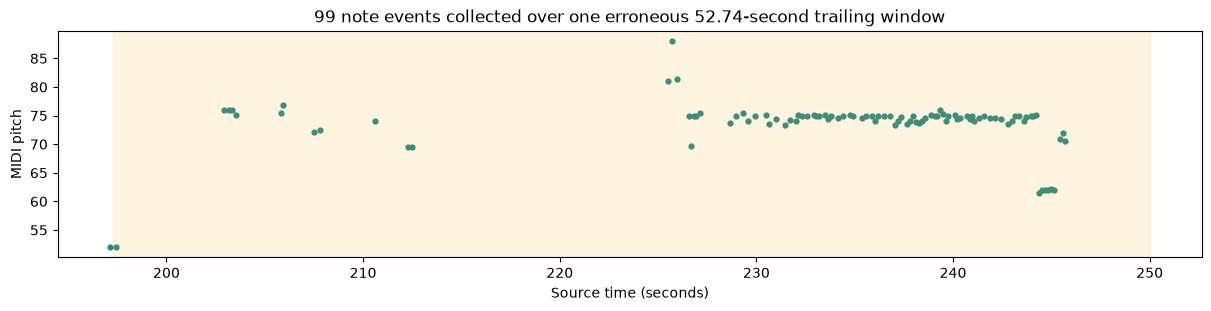

,split,sequence_index,track_id,first_beat_index,last_beat_index,real_beats,padded_beats,valid_targets
10845,train,10845,572381,640,647,8,0,8
10846,train,10846,572381,648,655,8,0,8
10847,train,10847,572381,656,663,8,0,8


,split,notes_truncated,maximum_original_notes,retained_sequences,real_beats
0,train,3523,18,23537,186594
1,validation,419,7,1429,11336
2,test,458,6,1798,14278


Retained arrays equal v3, with exactly one sequence removed and all note axes sliced to first four slots. All scalar/context/target/mask arrays checked byte for byte.


In [9]:
exclusion = read_json(OUT / 'outlier_exclusion.json')
display(pd.DataFrame([exclusion]))
source_name = f"track_{int(exclusion['track_id']):07d}"
outlier_source = ROOT / config['phase1_output_root'] / source_name / f'{source_name}_training_events.csv'
with outlier_source.open(encoding='utf-8',newline='') as stream:
    original_rows = [r for r in csv.DictReader(stream) if int(r['beat_index']) in exclusion['removed_beat_indices']]
display(pd.DataFrame([dict(beat_index=int(r['beat_index']), start_sec=float(r['start_sec']),
    end_sec=float(r['end_sec']), duration_sec=float(r['event_duration']),
    notes=len(json.loads(r['melody_midi'])), reference_chord=r['reference_chord']) for r in original_rows]))
outlier_event = next(r for r in original_rows if int(r['beat_index']) == exclusion['outlier_beat_index'])
onsets=np.array(json.loads(outlier_event['melody_relative_start']))+float(outlier_event['start_sec'])
overlaps=np.array(json.loads(outlier_event['melody_overlap_durations']))
pitches=np.array(json.loads(outlier_event['melody_midi']))
fig,ax=plt.subplots(figsize=(12,3),layout='constrained')
ax.scatter(onsets,pitches,s=12,color='#248A89')
ax.axvspan(float(outlier_event['start_sec']),float(outlier_event['end_sec']),alpha=.12,color='orange')
ax.set(title='99 note events collected over one erroneous 52.74-second trailing window',xlabel='Source time (seconds)',ylabel='MIDI pitch')
plt.show()
manifest=pd.read_csv(OUT/'sequence_manifest.csv',dtype={'track_id':str})
assert not ((manifest.track_id==exclusion['track_id']) & (manifest.last_beat_index>=min(exclusion['removed_beat_indices']))).any()
display(manifest.loc[manifest.track_id==exclusion['track_id']].tail(3))
display(pd.DataFrame([dict(split=k, notes_truncated=v['notes_truncated'], maximum_original_notes=v['max_observed_notes'],
    retained_sequences=v['sequences'],real_beats=v['beats']) for k,v in read_json(OUT/'preprocessing_statistics.json').items()]))
print(read_json(OUT/'four_note_reconstruction_validation.json')['policy'])


## 6. Four note slots per beat, padding and masks

This snapshot fixes **M=4**. For a beat with more than four notes, the existing encoder retains the first four in validated source order and truncates the rest. It does not choose four voices, the four longest notes or four simultaneous notes. Beats with fewer notes are padded. This is a lossy policy explicitly requested for the rebuilt dataset; aggregate truncation counts are shown below.

The 99-note trailing-window sequence is excluded before vocabulary fitting and sequence export. Source Phase 1 files remain unchanged. Note masks identify real retained slots; safe attention masks preserve dummy slot 0 for silent/padded beats. The dummy is not a note.

,training_max,saved_capacity,policy
0,18,4,Exactly four slots. Keep first four notes in validated source order; pad shorter lists. This is ...


,split,sequence_id,position_in_sequence,track_id,beat_index,is_padding,inputs__melody_silent,real_note_count,safe_attention_count
0,train,0,0,1079196,0,False,False,1,1
1,train,0,1,1079196,1,False,False,2,2
2,train,0,2,1079196,2,False,False,3,3
16,train,23536,0,917543,424,False,True,0,1
17,train,23536,1,917543,425,False,True,0,1
18,train,23536,2,917543,426,False,True,0,1
24,validation,0,0,156888,0,False,True,0,1
25,validation,0,1,156888,1,False,True,0,1
26,validation,0,2,156888,2,False,False,4,4
40,validation,1428,0,901684,608,False,True,0,1


,split,sequence_id,position_in_sequence,track_id,beat_index,is_padding,inputs__melody_silent,real_note_count,safe_attention_count
16,train,23536,0,917543,424,False,True,0,1
17,train,23536,1,917543,425,False,True,0,1
18,train,23536,2,917543,426,False,True,0,1
19,train,23536,3,917543,427,False,True,0,1
20,train,23536,4,917543,428,False,True,0,1
21,train,23536,5,917543,-1,True,True,0,1
22,train,23536,6,917543,-1,True,True,0,1
23,train,23536,7,917543,-1,True,True,0,1
24,validation,0,0,156888,0,False,True,0,1
25,validation,0,1,156888,1,False,True,0,1


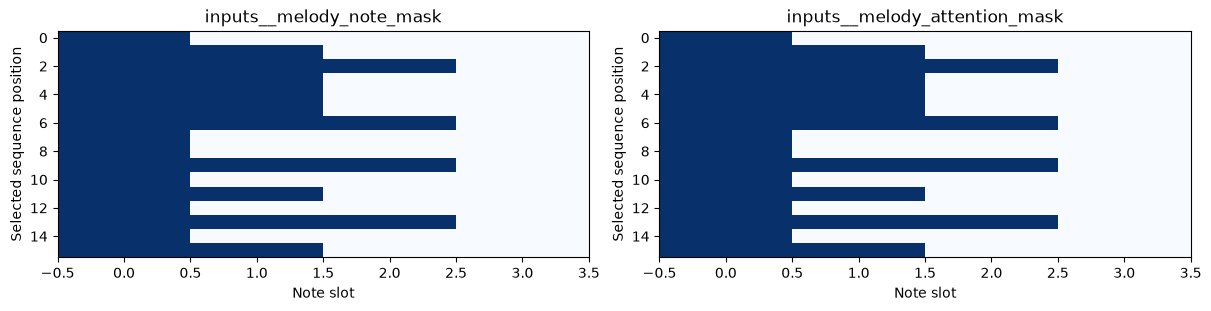

In [10]:
display(pd.DataFrame([dict(training_max=config['observed_training_max_notes'], saved_capacity=encoder.max_notes,
    policy=config['note_capacity_policy'])]))
mask_rows = sample[['split','sequence_id','position_in_sequence','track_id','beat_index','is_padding','inputs__melody_silent']].copy()
mask_rows['real_note_count'] = sample['inputs__melody_note_mask'].map(sum)
mask_rows['safe_attention_count'] = sample['inputs__melody_attention_mask'].map(sum)
display(mask_rows.groupby('track_id', sort=False).head(3))
display(mask_rows.loc[mask_rows.is_padding | (mask_rows.real_note_count == 0)].head(12))
fig, axes = plt.subplots(1, 2, figsize=(12,3), layout='constrained')
for ax, name in zip(axes, ['inputs__melody_note_mask','inputs__melody_attention_mask']):
    ax.imshow(np.asarray(sample.iloc[:16][name].tolist()), aspect='auto', interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
    ax.set(title=name, xlabel='Note slot', ylabel='Selected sequence position')
plt.show()


## 7. Targets and loss masking

Source-invalid, unsupported or training-unseen targets receive ID **-100** and decode to **IGNORE**. Padding is also ignored. A real beat can remain available as context while its target contributes no loss. Discarded reference labels cannot be recovered from the NPZ; the joined source event can explain why a real target was masked. Reference-derived basic chords make this a synthetic pseudo-label dataset rather than independent human ground truth.

In [11]:
display(pd.DataFrame([dict(split=r.split, track_id=r.track_id, beat_index=r.beat_index,
    source_reference=source_for(r)['reference_chord_canonical'], source_valid=source_for(r)['target_valid'],
    present_in_training_vocabulary=source_for(r)['reference_chord_canonical'] in encoder.targets.token_to_id,
    target_id=r['targets__target_chord_ids'], decoded=r.reference_chord_decoded,
    loss_mask=r['targets__target_loss_mask']) for _,r in real_sample.iterrows()]).head(24))
display(summary_table[['split','real_positions','supervised','padding']])
assert all((int(r['targets__target_chord_ids']) == -100) == (not r['targets__target_loss_mask']) for _,r in sample.iterrows())


,split,track_id,beat_index,source_reference,source_valid,present_in_training_vocabulary,target_id,decoded,loss_mask
0,train,1079196,0,G:maj,True,True,378,G:maj,True
1,train,1079196,1,G:maj,True,True,378,G:maj,True
2,train,1079196,2,G:maj,True,True,378,G:maj,True
3,train,1079196,3,G:maj,True,True,378,G:maj,True
4,train,1079196,4,D:maj,True,True,214,D:maj,True
5,train,1079196,5,D:maj,True,True,214,D:maj,True
6,train,1079196,6,D:maj,True,True,214,D:maj,True
7,train,1079196,7,D:maj,True,True,214,D:maj,True
8,train,1079196,8,E:min,True,True,260,E:min,True
9,train,1079196,9,E:min,True,True,260,E:min,True


,split,real_positions,supervised,padding
0,train,186594,184889,1702
1,validation,11336,11231,96
2,test,14278,14077,106


## 8. Chronological sequences, including the final padded windows

The saved length and stride are read from configuration. Each sequence belongs to one track and has every position represented in the CSV. First, second and final windows from every split are shown below. The final window of a split is not assumed to be padded: its actual masks determine that. Other tracks can also have padded final windows.

In [12]:
print('Sequence length:', config['sequence_length'], '| stride:', config['stride'])
window_cols = ['position_in_sequence','track_id','beat_index','basic_chord_decoded','inputs__basic_chord_ids',
    'reference_chord_decoded','targets__target_chord_ids','inputs__beat_attention_mask','targets__target_loss_mask','is_padding']
for (split, sequence), part in sample.groupby(['split','sequence_id'], sort=False):
    display(Markdown(f'**{split} / sequence {sequence}**'))
    display(part[window_cols].reset_index(drop=True))
    assert len(part) == config['sequence_length']
    assert part.track_id.nunique() == 1
    assert part.position_in_sequence.tolist() == list(range(config['sequence_length']))
    beats = part.loc[~part.is_padding, 'beat_index'].tolist()
    assert beats == sorted(beats)


Sequence length: 8 | stride: 8


**train / sequence 0**

,position_in_sequence,track_id,beat_index,basic_chord_decoded,inputs__basic_chord_ids,reference_chord_decoded,targets__target_chord_ids,inputs__beat_attention_mask,targets__target_loss_mask,is_padding
0,0,1079196,0,G,69,G:maj,378,True,True,False
1,1,1079196,1,G,69,G:maj,378,True,True,False
2,2,1079196,2,G,69,G:maj,378,True,True,False
3,3,1079196,3,G,69,G:maj,378,True,True,False
4,4,1079196,4,D,37,D:maj,214,True,True,False
5,5,1079196,5,D,37,D:maj,214,True,True,False
6,6,1079196,6,D,37,D:maj,214,True,True,False
7,7,1079196,7,D,37,D:maj,214,True,True,False


**train / sequence 1**

,position_in_sequence,track_id,beat_index,basic_chord_decoded,inputs__basic_chord_ids,reference_chord_decoded,targets__target_chord_ids,inputs__beat_attention_mask,targets__target_loss_mask,is_padding
0,0,1079196,8,Em,54,E:min,260,True,True,False
1,1,1079196,9,Em,54,E:min,260,True,True,False
2,2,1079196,10,Em,54,E:min,260,True,True,False
3,3,1079196,11,Em,54,E:min,260,True,True,False
4,4,1079196,12,C,25,C:maj,141,True,True,False
5,5,1079196,13,C,25,C:maj,141,True,True,False
6,6,1079196,14,C,25,C:maj,141,True,True,False
7,7,1079196,15,C,25,C:maj,141,True,True,False


...

,position_in_sequence,track_id,beat_index,basic_chord_decoded,inputs__basic_chord_ids,reference_chord_decoded,targets__target_chord_ids,inputs__beat_attention_mask,targets__target_loss_mask,is_padding
0,0,156887,0,N,2,N,2,True,True,False
1,1,156887,1,N,2,N,2,True,True,False
2,2,156887,2,Am,15,A:min,57,True,True,False
3,3,156887,3,Am,15,A:min,57,True,True,False
4,4,156887,4,Am,15,A:min,57,True,True,False
5,5,156887,5,Am,15,A:min,57,True,True,False
6,6,156887,6,Am,15,A:min,57,True,True,False
7,7,156887,7,Am,15,A:min,57,True,True,False


**test / sequence 1**

,position_in_sequence,track_id,beat_index,basic_chord_decoded,inputs__basic_chord_ids,reference_chord_decoded,targets__target_chord_ids,inputs__beat_attention_mask,targets__target_loss_mask,is_padding
0,0,156887,8,C,25,C:maj,141,True,True,False
1,1,156887,9,C,25,C:maj,141,True,True,False
2,2,156887,10,F,57,F:maj,315,True,True,False
3,3,156887,11,F,57,F:maj,315,True,True,False
4,4,156887,12,F,57,F:maj,315,True,True,False
5,5,156887,13,F,57,F:maj,315,True,True,False
6,6,156887,14,E,50,E:maj,250,True,True,False
7,7,156887,15,E,50,E:maj,250,True,True,False


**test / sequence 1797**

,position_in_sequence,track_id,beat_index,basic_chord_decoded,inputs__basic_chord_ids,reference_chord_decoded,targets__target_chord_ids,inputs__beat_attention_mask,targets__target_loss_mask,is_padding
0,0,855373,336,A,6,A:maj,45,True,True,False
1,1,855373,337,A,6,A:maj,45,True,True,False
2,2,855373,338,A,6,A:maj,45,True,True,False
3,3,855373,339,A,6,A:maj,45,True,True,False
4,4,855373,340,N,2,N,2,True,True,False
5,5,855373,341,N,2,N,2,True,True,False
6,6,855373,-1,PAD,0,IGNORE,-100,False,False,True
7,7,855373,-1,PAD,0,IGNORE,-100,False,False,True


## 9. Re-run the saved encoder for selected source beats

This is an in-memory comparison using the existing implementation and saved mappings, not a new preprocessing pipeline. Every directly encoded input and target is compared to its CSV cell. Sequence-relative bar offsets are constructed later by the sequence builder and are checked against NPZ in the next section.

In [13]:
encoding_checks = 0
for _, row in real_sample.iterrows():
    event = source_for(row)
    for group, encoded in [('inputs', encoder.encode_inputs(event['input_snapshot'])), ('targets', encoder.encode_target(event))]:
        for name, expected in encoded.items():
            expected = np.asarray(expected)
            actual = np.asarray(row[f'{group}__{name}'], dtype=expected.dtype)
            np.testing.assert_array_equal(actual, expected, err_msg=f'{row.track_id} beat {row.beat_index}: {name}')
            encoding_checks += 1
print('Source-to-CSV input/target comparisons passed:', encoding_checks)


Source-to-CSV input/target comparisons passed: 1560


## 10. Verify selected CSV tensors against SavedSequenceDataset

One archive is loaded at a time and released before the next. All tensor columns for every selected position are compared with the official Dataset output, casting text values back to the original dtype and comparing bytes. Sequence-level genre vectors are checked on every position. The existing full-export validation report covers every position; this notebook adds executable checks for its displayed examples.

In [14]:
tensor_keys = [k for k in sample.columns if k.startswith(('inputs__','targets__'))]
npz_checks = 0
inventories = []
for split in summary:
    dataset = SavedSequenceDataset(OUT / f'{split}_sequences.npz')
    inventories.extend(dict(split=split, name=k, shape=list(v.shape), dtype=str(v.dtype)) for k,v in dataset.arrays.items())
    for _, row in sample.loc[sample.split == split].iterrows():
        item = dataset[int(row.sequence_id)]
        p = int(row.position_in_sequence)
        assert item['metadata']['track_id'] == row.track_id
        assert int(item['metadata']['beat_indices'][p]) == row.beat_index
        for key in tensor_keys:
            group, name = key.split('__',1)
            expected = item[group][name].numpy()
            expected = expected if name == 'genre_features' else expected[p]
            actual = np.asarray(row[key], dtype=expected.dtype)
            assert actual.shape == expected.shape and actual.tobytes() == expected.tobytes(), (split,row.sequence_id,p,key)
            npz_checks += 1
    del dataset, item
    gc.collect()
display(pd.DataFrame(inventories))
print('CSV-to-SavedSequenceDataset tensor comparisons passed:', npz_checks)


,split,name,shape,dtype
0,train,inputs__basic_chord_ids,"[23537, 8]",int64
1,train,inputs__basic_root_ids,"[23537, 8]",int64
2,train,inputs__basic_quality_ids,"[23537, 8]",int64
3,train,inputs__previous_basic_chord_ids,"[23537, 8]",int64
4,train,inputs__next_basic_chord_ids,"[23537, 8]",int64
...,...,...,...,...
85,test,inputs__relative_bar_number,"[1798, 8]",float32
86,test,targets__target_chord_ids,"[1798, 8]",int64
87,test,targets__target_loss_mask,"[1798, 8]",bool
88,test,track_ids,[1798],<U6


CSV-to-SavedSequenceDataset tensor comparisons passed: 2016


## 11. All-track overview and validation

Counts below are computed from the CSV scan and cross-checked with the per-track index and export report. Chord counts include only real beats. Split assignments use connected artist/album/recording groups; feature and target vocabularies were fitted on training tracks only. This notebook does not resplit or refit them.

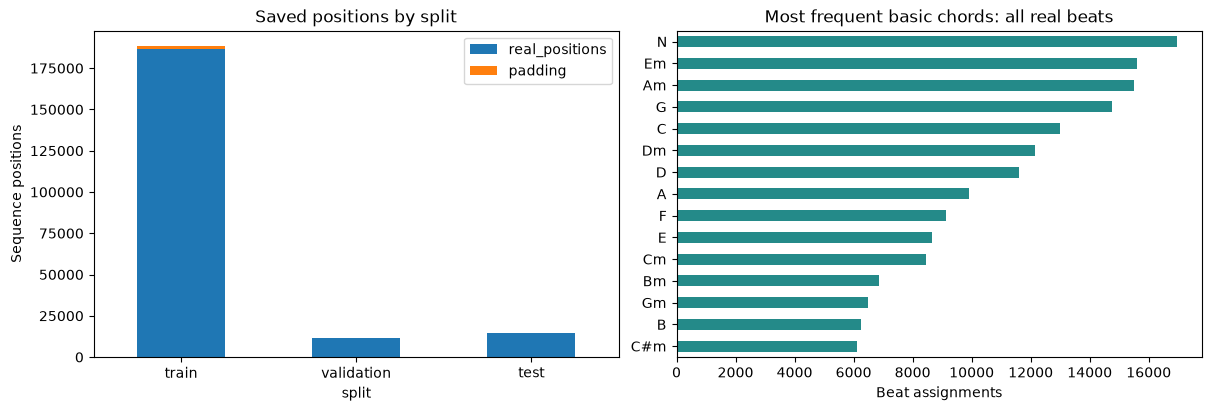

,split,rows,real_positions,padding,supervised,tracks,sequences
0,train,188296,186594,1702,184889,470,23537
1,validation,11432,11336,96,11231,23,1429
2,test,14384,14278,106,14077,32,1798


,check,result
0,Selected source encoder comparisons,1560
1,Selected NPZ tensor comparisons,2016
2,Prior complete export validation,passed
3,Full-export array comparison,All 30 arrays in each split reconstructed byte for byte; repeated genre vectors checked on every...


Existing preprocessing artifacts unchanged (size and modification-time check).


In [15]:
for split, state in summary.items():
    per_track = index.loc[index.split == split]
    assert state['rows'] == int(per_track.real_positions.sum() + per_track.padded_positions.sum())
    assert len(state['sequences']) == int(per_track.sequences.sum())
    assert state['tracks'] == set(per_track.track_id)
    assert state['rows'] == len(state['sequences']) * config['sequence_length']
assert sum(s['rows'] for s in summary.values()) == export_report['rows']
assert sum(s['padding'] for s in summary.values()) == export_report['padded_positions']
track_sets = [s['tracks'] for s in summary.values()]
assert all(not a.intersection(b) for i,a in enumerate(track_sets) for b in track_sets[i+1:])
fig, axes = plt.subplots(1, 2, figsize=(12,4), layout='constrained')
summary_table.set_index('split')[['real_positions','padding']].plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set(title='Saved positions by split', ylabel='Sequence positions')
chords = {}
for state in summary.values():
    for label,count in state['basic'].items(): chords[label] = chords.get(label,0)+count
pd.Series(chords).nlargest(15).sort_values().plot.barh(ax=axes[1], color='#248A89')
axes[1].set(title='Most frequent basic chords: all real beats', xlabel='Beat assignments')
plt.show()
display(summary_table)
display(pd.DataFrame([{'check':'Selected source encoder comparisons', 'result':encoding_checks},
    {'check':'Selected NPZ tensor comparisons', 'result':npz_checks},
    {'check':'Prior complete export validation', 'result':export_report['status']},
    {'check':'Full-export array comparison', 'result':export_report['array_verification']}]))
# Detect changes without rereading the 2 GB CSV for another hash.
assert all((p.stat().st_size,p.stat().st_mtime_ns) == state for p,state in protected.items())
print('Existing preprocessing artifacts unchanged (size and modification-time check).')


## 12. Training artifacts and interpretation

Use the existing **train_sequences.npz**, **validation_sequences.npz** and **test_sequences.npz** with `SavedSequenceDataset` for model training. The readable CSV explains their contents; it should not be supplied as an unfiltered feature matrix because it also contains targets, metadata and decoded inspection columns.

The displayed pipeline is: source beat events → saved categorical mappings → pitch and beat-relative timing → note padding and safe attention masks → context features → separate target IDs and loss masks → track-preserving padded sequences. No Transformer, optimizer, loss computation or training is implemented here.